# 04 — 24-Hour Station Load Demand Forecasting
Uses **XGBoost Regressor** with temporal, meteorological, and lag features to predict hourly station electrical and heating load demand.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

PROJECT_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
sys.path.insert(0, str(PROJECT_ROOT))


## 1. Load Evaluation Metrics and Predictions


In [2]:
preds_path = PROJECT_ROOT / "results" / "forecasts" / "forecast_predictions.csv"
metrics_path = PROJECT_ROOT / "results" / "forecasts" / "forecast_metrics.json"

df_preds = pd.read_csv(preds_path)
with open(metrics_path) as f:
    metrics = json.load(f)

print("Load Forecast Metrics:")
print(f"  MAE:  {metrics['load']['MAE']:.3f} kW")
print(f"  RMSE: {metrics['load']['RMSE']:.3f} kW")
print(f"  R²:   {metrics['load']['R2']:.4f}")
print(f"  MAPE: {metrics['load']['MAPE']:.2f}%")


Load Forecast Metrics:
  MAE:  2.061 kW
  RMSE: 2.633 kW
  R²:   0.9565
  MAPE: 4.31%


## 2. Actual vs Predicted Load (Sample Week)


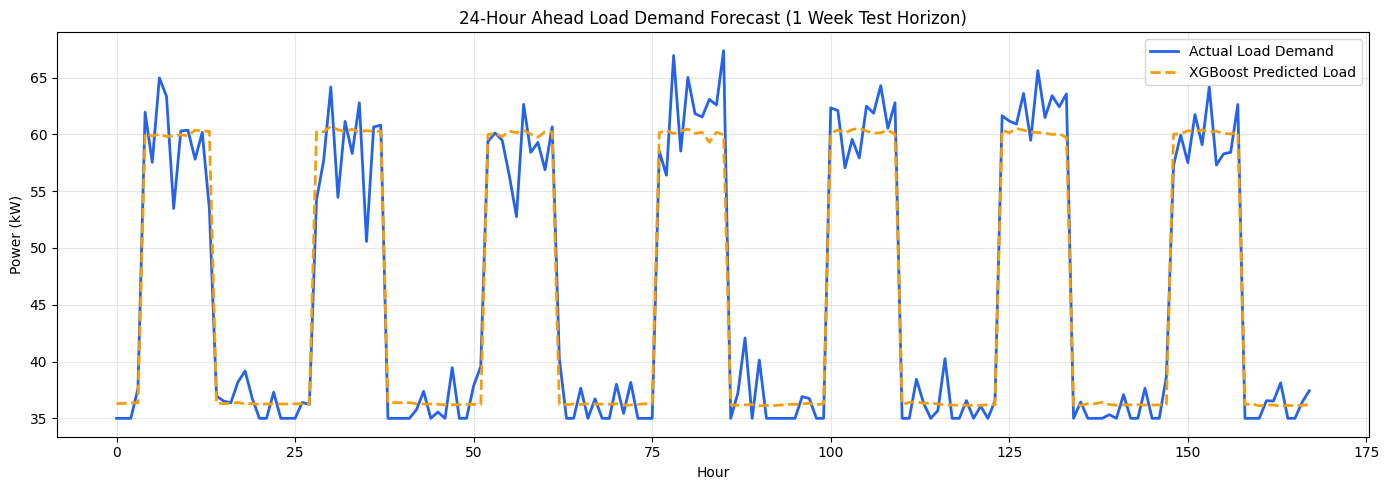

In [3]:
sample = df_preds.head(168)
plt.figure(figsize=(14, 5))
plt.plot(sample['load_actual'], label='Actual Load Demand', color='#2563eb', lw=2)
plt.plot(sample['load_pred'], label='XGBoost Predicted Load', color='#f59e0b', linestyle='--', lw=2)
plt.title("24-Hour Ahead Load Demand Forecast (1 Week Test Horizon)")
plt.xlabel("Hour")
plt.ylabel("Power (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
